# ADP 21회 상황형 연습 - 풀이

**상황형 재구성 연습·예시 풀이이며 공식 원문/정답이 아닙니다.**

출처: 기출문제 모음 PDF p.2

원 자료 조건: 원 데이터가 첨부되지 않아 동일 컬럼·분석 주제의 합성 연습 자료를 제공합니다. 수치 정답은 원 시험과 다릅니다.

문제는 동봉 상황형 문제지와 같습니다. 원문은 문항목록.json·추가_문항명세.json에 보존합니다. 순서대로 실행하며 각 대문항에서 고정한 자료·전처리·분할을 후속 문항에 재사용합니다. 통계 답안은 선정 근거 → 가정·가설 → 통계량·p-value → 기각 여부·상황 해석 순서로 작성합니다. 확률·구간 추정·관리도 문항에 불필요한 귀무가설을 만들지 않습니다.

실행: 해당 회차 폴더에서 위에서 아래로 실행합니다. 가설검정_답안.json은 실제 계산한 가설·수치·결론 기록입니다.

In [1]:
from pathlib import Path
import sys, numpy as np, pandas as pd
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from scipy import stats
import statsmodels.api as sm
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier,GradientBoostingClassifier
from sklearn.svm import SVC
from IPython.display import display
# repository root 또는 회차 폴더에서 탐색; 경로를 하드코딩하지 않음.
ROOT=next(p for p in [Path.cwd()]+list(Path.cwd().parents) if (p/'기출문제/공통/reconstruction.py').exists())
sys.path.insert(0,str(ROOT));sys.path.insert(0,str(ROOT/'기출문제/공통'))
from reconstruction import *
from matplotlib import font_manager
font_path=ROOT/'기출문제/공통/NanumGothic-Regular.ttf'
font_manager.fontManager.addfont(str(font_path))
plt.rcParams['font.family']='NanumGothic';plt.rcParams['axes.unicode_minus']=False
HERE=ROOT/'기출문제'/'21회';DATA=HERE/'data';OUT=HERE/'실행결과';OUT.mkdir(exist_ok=True)
def load(name):return pd.read_csv(DATA/name)
print('데이터 종류: 합성 복원 연습 자료, 원 시험 데이터가 아님')

# 상황형 답안 기록 초기화
_SCENARIO_ROOT=next(p for p in [Path.cwd()]+list(Path.cwd().parents) if (p/'기출문제/공통/scenario_inference.py').is_file())
sys.path.insert(0,str(_SCENARIO_ROOT/'기출문제/공통'))
from scenario_inference import (reset_reports, set_question, report_test, report_anova,
    report_correlations, report_adf, report_residuals, report_regression_diagnostics)
reset_reports(OUT)


데이터 종류: 합성 복원 연습 자료, 원 시험 데이터가 아님


## 1. 학생 성적 범주 예측

학교는 student 자료의 특성으로 성적 범주를 예측하려 한다. 동일 7:3 층화 분할과 전처리를 모형 비교에 재사용한다.

자료: student.csv

### 1-1

결측·분포와 범주 특성을 확인하시오. 두 가지 결측 대응 방안과 범주 표현의 선택 근거를 설명하시오.

**판단 및 풀이 근거**

수치 median과 범주 mode 대치 또는 완전 사례 제거를 비교합니다. 합성 자료에는 결측이 없으므로 존재하지 않는 결측 개선을 주장하지 않습니다.

**실행 답안**

아래 코드는 이 문항의 산출물과 수치를 계산합니다. 결과와 위 판단 근거를 연결해 답안을 작성합니다.

school        0
sex           0
paid          0
activities    0
famrel        0
freetime      0
goout         0
dalc          0
walc          0
health        0
absences      0
grade         0
dtype: int64
       school  sex paid  ...      health    absences       grade
count     395  395  395  ...  395.000000  395.000000  395.000000
unique      2    2    2  ...         NaN         NaN         NaN
top        GP    M  yes  ...         NaN         NaN         NaN
freq      204  200  202  ...         NaN         NaN         NaN
mean      NaN  NaN  NaN  ...    3.070886    5.088608   14.078493
std       NaN  NaN  NaN  ...    1.396165    2.209749    2.548853
min       NaN  NaN  NaN  ...    1.000000    0.000000    6.384986
25%       NaN  NaN  NaN  ...    2.000000    3.000000   12.259450
50%       NaN  NaN  NaN  ...    3.000000    5.000000   14.236009
75%       NaN  NaN  NaN  ...    4.000000    7.000000   15.939104
max       NaN  NaN  NaN  ...    5.000000   13.000000   20.000000

[11 rows x 12 

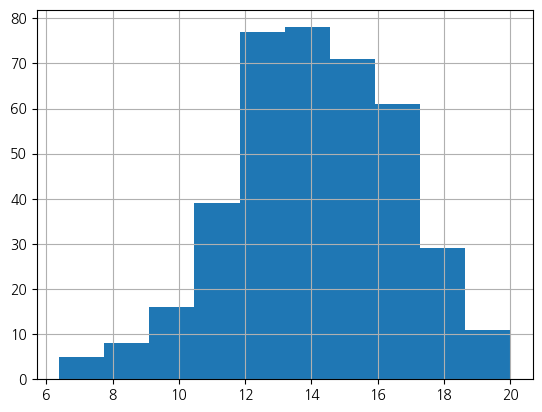

In [2]:
set_question('1-1')
student=load('student.csv');print(student.isna().sum());print(student.describe(include='all'));student.grade.hist();plt.show()

### 1-2

랜덤·그룹·시간 분할의 차이를 사용 상황과 연결하시오. 7:3 층화 분할로 커널·트리 앙상블·부스팅 후보를 비교하고 선택 근거를 제시하시오.

**판단 및 풀이 근거**

원문 요구 SVM·RandomForest·XGBoost를 모두 실제 실행합니다. XGBoost를 위해 클래스 코드를 0부터 연속 정수로 지정합니다.

**실행 답안**

아래 코드는 이 문항의 산출물과 수치를 계산합니다. 결과와 위 판단 근거를 연결해 답안을 작성합니다.

/workspace/scratch/db733eda61a1/adp-study/기출문제/공통/reconstruction.py:141: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.plot([0, 1], [0, 1], '--'); ax.set(xlabel='FPR', ylabel='TPR'); ax.legend(); plt.show()


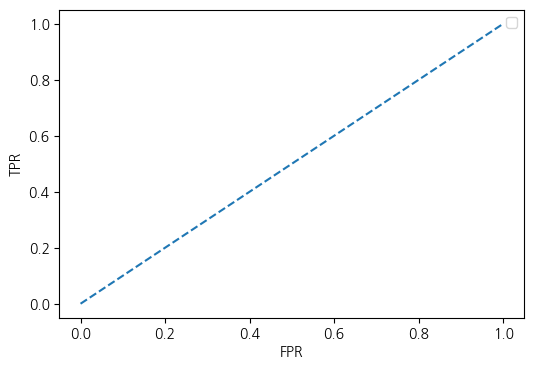

           model  accuracy  f1_weighted
0            svm  0.588235     0.552976
1  random_forest  0.504202     0.462097
2        xgboost  0.563025     0.545229


In [3]:
set_question('1-2')
student['grade_class']=pd.cut(student.grade,[-np.inf,10,15,np.inf],labels=['low','middle','high'],right=False)
student_features=[c for c in student if c not in ['grade','grade_class']]
from xgboost import XGBClassifier
student['grade_class']=student['grade_class'].cat.codes
student_scores,_,_,_=classify(student,'grade_class',student_features,OUT,algorithms={'svm':SVC(probability=True,random_state=1234),'random_forest':RandomForestClassifier(n_estimators=50,random_state=1234),'xgboost':XGBClassifier(n_estimators=50,max_depth=3,random_state=1234,n_jobs=1)})

### 1-3

평가 결과로 확인된 장단점과 개선 방안을 제시하시오. 학교 운영에 적용할 때 입력 품질·공정성·일반화 점검 항목을 설명하시오.

**판단 및 풀이 근거**

편향·일반화·학습 전처리 재사용·데이터 변화 감시가 핵심입니다.

**실행 답안**

아래 코드는 이 문항의 산출물과 수치를 계산합니다. 결과와 위 판단 근거를 연결해 답안을 작성합니다.

In [4]:
set_question('1-3')
print(student_scores);print('학교·학생 반복 자료는 Group CV, 미래 예측은 시간 CV를 사용. 정확도 외 macro F1/오류비용을 확인. test로 반복 튜닝하지 않음.')

           model  accuracy  f1_weighted
0            svm  0.588235     0.552976
1  random_forest  0.504202     0.462097
2        xgboost  0.563025     0.545229
학교·학생 반복 자료는 Group CV, 미래 예측은 시간 CV를 사용. 정확도 외 macro F1/오류비용을 확인. test로 반복 튜닝하지 않음.


## 2. 수치 목표 예측 비교

별도 regression 자료에서 과적합 억제가 예측에 도움이 되는지 확인하려 한다. 8:2 보류 구간과 같은 학습 내부 CV를 모든 비교에서 유지한다.

자료: regression.csv

### 2-1

8:2 분할로 선형 기준 모형을 적합하고 보류 R²·RMSE를 제시하시오. 기준 모형으로서의 의미를 설명하시오.

**판단 및 풀이 근거**

특성 표준화도 train에서만 적합합니다.

**실행 답안**

아래 코드는 이 문항의 산출물과 수치를 계산합니다. 결과와 위 판단 근거를 연결해 답안을 작성합니다.

In [5]:
set_question('2-1')
from sklearn.linear_model import LinearRegression,Ridge,Lasso
reg=load('regression.csv');X=reg.drop(columns='y');y=reg.y
train,test=train_test_split(np.arange(len(reg)),test_size=.2,random_state=1234)
ols=Pipeline([('scaler',StandardScaler()),('model',LinearRegression())]).fit(X.iloc[train],y.iloc[train])
print({'R2':r2_score(y.iloc[test],ols.predict(X.iloc[test])),'RMSE':np.sqrt(mean_squared_error(y.iloc[test],ols.predict(X.iloc[test])))})

{'R2': 0.919113872533377, 'RMSE': np.float64(1.1451446474395133)}


### 2-2

계수 크기를 억제하는 두 벌점 방안을 비교하시오. alpha=0~1을 .1 간격으로 탐색하되 train CV로 선택하고 보류 R²·RMSE를 보고하시오. alpha=0의 처리와 희소화 차이를 설명하시오.

**판단 및 풀이 근거**

원문 test R²로 alpha를 고르는 흐름은 test 선정 누출이므로 CV로 보완합니다. alpha=0 OLS도 동일 CV에서 비교해 높은 쪽으로 최종 선택합니다.

**실행 답안**

아래 코드는 이 문항의 산출물과 수치를 계산합니다. 결과와 위 판단 근거를 연결해 답안을 작성합니다.

In [6]:
set_question('2-2')
from src.MachineLearning.Optimization.grid_search import run_grid_search
from sklearn.model_selection import KFold,cross_val_score
folds_reg=list(KFold(n_splits=3,shuffle=True,random_state=1234).split(X.iloc[train]))
ols_cv=cross_val_score(Pipeline([('scaler',StandardScaler()),('model',LinearRegression())]),X.iloc[train],y.iloc[train],cv=folds_reg,scoring='r2').mean()
regularized=[]
for name,est in [('ridge',Ridge()),('lasso',Lasso(max_iter=5000))]:
    pipe=Pipeline([('scaler',StandardScaler()),('model',est)])
    result=run_grid_search(X.iloc[train],y.iloc[train],pipe,task='regression',overrides={'scoring':'r2','search_space':{'model__alpha':np.arange(.1,1.01,.1).tolist()}})
    assert [(a.tolist(),b.tolist()) for a,b in folds_reg]==[(f['train_indices'].tolist(),f['validation_indices'].tolist()) for f in result.folds]
    selected_model=ols if ols_cv>=result.best_score else result.model
    selected_alpha=0. if ols_cv>=result.best_score else result.best_params['model__alpha']
    pred=selected_model.predict(X.iloc[test]);regularized.append({'model':name,'best_alpha':selected_alpha,'test_R2':r2_score(y.iloc[test],pred),'test_RMSE':np.sqrt(mean_squared_error(y.iloc[test],pred))})
print(pd.DataFrame(regularized));print('alpha=0 OLS의 동일 train CV R2:',ols_cv)

   model  best_alpha   test_R2  test_RMSE
0  ridge         0.0  0.919114   1.145145
1  lasso         0.1  0.939402   0.991179
alpha=0 OLS의 동일 train CV R2: 0.9425407171608623


## 3. 곡선 관계 설명

별도 polynomial 자료의 x와 y 관계가 직선으로 충분한지 살피려 한다.

자료: polynomial.csv

### 3-1

1·2·3차 설명 모형의 산점도·추정 계수·곡선을 비교하시오. 복잡도 증가의 장단점과 탐색 그림만으로 일반화 우열을 단정할 수 없는 이유를 설명하시오.

**판단 및 풀이 근거**

이 문항은 관계 탐색의 적합선입니다. 최적 예측 차수 선정에는 학습 CV와 별도 test가 필요합니다.

**실행 답안**

아래 코드는 이 문항의 산출물과 수치를 계산합니다. 결과와 위 판단 근거를 연결해 답안을 작성합니다.

1 [0.97480183] 5.006556462335558
2 [0.97480183 0.99820704] 1.9514379357784457
3 [0.9344132  0.99820704 0.00733225] 1.9514379357784466


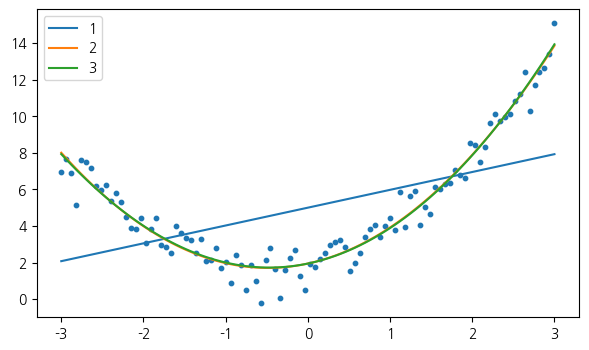

In [7]:
set_question('3-1')
from sklearn.preprocessing import PolynomialFeatures
poly=load('polynomial.csv');fig,ax=plt.subplots(figsize=(7,4));ax.scatter(poly.x,poly.y,s=10)
for degree in [1,2,3]:
    m=Pipeline([('poly',PolynomialFeatures(degree=degree,include_bias=False)),('model',LinearRegression())]).fit(poly[['x']],poly.y)
    print(degree,m.named_steps['model'].coef_,m.named_steps['model'].intercept_);ax.plot(poly.x,m.predict(poly[['x']]),label=str(degree))
ax.legend();plt.show()

## 4. 두 집단 요인의 효과

독립 관측의 y가 group(a/b/c/d)과 band(high/low)에 따라 달라지는지 조사한다. band는 연습 조건상 x>=0으로 만든 범주다. 정규 오차·등분산·셀별 독립 관측을 작업 가정으로 두며 유의수준은 5%다.

자료: anova.csv

### 4-1

group 효과가 band에 따라 달라지는지 평가할 방법을 선택하시오. 두 주효과와 상호작용 각각의 귀무·대립가설, 통계량·p-value·기각 여부를 제시하고 셀 평균과 함께 결론을 작성하시오. 두 번째 요인을 보완한 복원 가정도 명시하시오.

**판단 및 풀이 근거**

독립 집단의 수치 반응을 설명하는 요인 모형을 선택한다. 한 요인이면 H0: 모든 집단 평균이 같다, H1: 적어도 하나 다르다. 두 요인이면 주효과와 상호작용의 가설·p값을 각각 구분한다. 정규 오차·등분산은 작업 가정이며 적합성을 검토한다.

**계산·해석 상세**

PDF는 수치 두 변수와 범주 한 변수만 명시하여 두 번째 요인을 보완했습니다. 실제 문항이 ANCOVA일 가능성도 있어 복원 가정을 분리합니다.

**실행 답안**

아래 코드는 이 문항의 산출물과 수치를 계산합니다. 가설·통계량·p-value·기각 여부·상황 결론을 함께 출력하며 수치는 실행 결과에 따라 결정합니다.

In [8]:
set_question('4-1')
aov=load('anova.csv');aov['band']=np.where(aov.x>=0,'high','low');anova(aov,'y','group','band')

# 상황형 요구: 가설·실제 수치·기각 여부·맥락 결론
_aov_model=anova(aov,'y','group','band')
report_anova(_aov_model,'y',['group', 'band'])

                      sum_sq    df          F        PR(>F)
C(group)          157.510280   3.0  55.613639  1.346589e-20
C(band)             1.648606   1.0   1.746266  1.896237e-01
C(group):C(band)    2.876668   3.0   1.015692  3.894904e-01
Residual           86.854867  92.0        NaN           NaN
유의하면 적어도 한 평균/효과가 다릅니다. 모든 쌍이 다르다는 뜻은 아닙니다.
합성 자료의 예시 추론. 정규성·등분산·독립성 및 표본 설계를 실제 자료에서 재검증하세요.
                      sum_sq    df          F        PR(>F)
C(group)          157.510280   3.0  55.613639  1.346589e-20
C(band)             1.648606   1.0   1.746266  1.896237e-01
C(group):C(band)    2.876668   3.0   1.015692  3.894904e-01
Residual           86.854867  92.0        NaN           NaN
유의하면 적어도 한 평균/효과가 다릅니다. 모든 쌍이 다르다는 뜻은 아닙니다.
합성 자료의 예시 추론. 정규성·등분산·독립성 및 표본 설계를 실제 자료에서 재검증하세요.
{
  "question": "4-1",
  "method": "독립 집단 요인 모형의 Type II F 검정: group 주효과",
  "H0": "group 주효과가 없다",
  "H1": "group 주효과가 있다",
  "statistic": 55.61363923693268,
  "p_value": 1.3465886038314801e-20,
  "alpha": 0.0